# RectPack exploration

Rectpack is a collection of heuristic algorithms for solving the 2D knapsack problem, also known as the bin packing problem. In essence packing a set of rectangles into the smallest number of bins. 

From https://github.com/secnot/rectpack

In [ ]:
import time
from rectpack import newPacker, MaxRectsBssf, MaxRectsBaf, SkylineBl, GuillotineBafSas
from rectpack import SORT_AREA, SORT_SSIDE, SORT_NONE
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# These options sort by descending area, descending shortest side, or leave the rectangles in their input order, respectively.
SORT_LABELS = {
    SORT_AREA: "Area",
    SORT_SSIDE: "Shortest side",
    SORT_NONE: "Input order",
}

Build a reusable packing function

In [16]:
def run_pack(
    parts,
    algorithm,
    sort_algo=SORT_AREA,
    rotation=True,
    sheet_size=(2500, 1250),
    available_sheets=3,
):
    sheet_width, sheet_height = sheet_size

    packer = newPacker(
        pack_algo=algorithm,
        sort_algo=sort_algo,
        rotation=rotation,
    )

    for part_id, width, height in parts:
        packer.add_rect(width, height, rid=part_id)

    packer.add_bin(
        sheet_width,
        sheet_height,
        count=available_sheets,
    )

    start = time.perf_counter()
    packer.pack()
    runtime = time.perf_counter() - start

    placements = packer.rect_list()
    used_sheets = packer.bin_list()

    packed_area = sum(
        w * h for _, _, _, w, h, _ in placements
    )
    used_area = sum(w * h for w, h in used_sheets)

    return {
        "algorithm": algorithm.__name__,
        "sort": SORT_LABELS.get(sort_algo, "Custom"),
        "rotation": rotation,
        "parts_packed": len(placements),
        "parts_total": len(parts),
        "sheets_used": len(used_sheets),
        "packed_area": packed_area,
        "utilisation": packed_area / used_area if used_area else 0,
        "runtime_seconds": runtime,
        "placements": placements,
        "used_sheets": used_sheets,
    }

Generate repeatable, varied datasets
This generates synthetic parts with different proportions: strips, tall parts, large rectangles and smaller fillers.
Deliberately exploratory datasets, not a claim about typical metal orders.

The seed recreates exactly the same dataset later.

In [17]:
import random

def make_parts(seed, count=35):
    rng = random.Random(seed)
    parts = []

    for i in range(count):
        shape_type = rng.choice(
            ["wide", "tall", "large", "small"]
        )

        if shape_type == "wide":
            width = rng.randrange(700, 1501, 50)
            height = rng.randrange(150, 401, 50)

        elif shape_type == "tall":
            width = rng.randrange(150, 401, 50)
            height = rng.randrange(700, 1201, 50)

        elif shape_type == "large":
            width = rng.randrange(600, 1201, 50)
            height = rng.randrange(450, 851, 50)

        else:
            width = rng.randrange(150, 601, 50)
            height = rng.randrange(150, 501, 50)

        parts.append((f"P{i + 1:02d}", width, height))

    return parts

Compare algorithms

In [21]:
algorithms = [
    MaxRectsBssf,
    MaxRectsBaf,
    SkylineBl,
    GuillotineBafSas,
]

records = []
runs = {}

for seed in range(30):
    case_parts = make_parts(seed)

    for algorithm in algorithms:
        result = run_pack(
            parts=case_parts,
            algorithm=algorithm,
            available_sheets=3,
        )

        runs[(seed, algorithm.__name__)] = result

        records.append({
            "seed": seed,
            "algorithm": result["algorithm"],
            "parts_packed": result["parts_packed"],
            "parts_total": result["parts_total"],
            "sheets_used": result["sheets_used"],
            "packed_area": result["packed_area"],
            "utilisation": result["utilisation"],
            "runtime_seconds": result["runtime_seconds"],
        })

benchmark = pd.DataFrame(records)
# benchmark["utilisation"] = benchmark["utilisation"].map("{:.1%}".format)
# benchmark["runtime_seconds"] = benchmark["runtime_seconds"].map("{:.4f}".format)

benchmark.head()

,seed,algorithm,parts_packed,parts_total,sheets_used,packed_area,utilisation,runtime_seconds
0,0,MaxRectsBssf,22,35,3,8890000,0.948267,0.001347
1,0,MaxRectsBaf,19,35,3,8647500,0.922400,0.000795
2,0,SkylineBl,18,35,3,8622500,0.919733,0.003371
3,0,GuillotineBafSas,21,35,3,8525000,0.909333,0.000655
4,1,MaxRectsBssf,24,35,3,8405000,0.896533,0.001011


Find a case where the 4 algorithms disagree

In [24]:
spread = benchmark.groupby("seed").agg(
    packed_count_variants=("parts_packed", "nunique"),
    packed_area_variants=("packed_area", "nunique"),
    sheet_count_variants=("sheets_used", "nunique"),
)

different_cases = spread[
    (spread > 1).any(axis=1)
]

if different_cases.empty:
    selected_seed = 0
    print(
        "No differences in these summary metrics. "
        "Inspect layouts or increase the number of seeds."
    )
else:
    selected_seed = int(different_cases.index[0])
    print(f"First differing case: seed {selected_seed}")

case_summary = benchmark[
    benchmark["seed"] == selected_seed
].sort_values(
    ["parts_packed", "packed_area"],
    ascending=False,
)

case_summary["utilisation"] = case_summary["utilisation"].map("{:.1%}".format)
case_summary["packed_area"] = case_summary["packed_area"].map("{:,.0f}".format)
case_summary["runtime_seconds"] = case_summary["runtime_seconds"].map("{:.4f}".format)

case_summary

First differing case: seed 0


,seed,algorithm,parts_packed,parts_total,sheets_used,packed_area,utilisation,runtime_seconds
0,0,MaxRectsBssf,22,35,3,"8,890,000",94.8%,0.0013
3,0,GuillotineBafSas,21,35,3,"8,525,000",90.9%,0.0007
1,0,MaxRectsBaf,19,35,3,"8,647,500",92.2%,0.0008
2,0,SkylineBl,18,35,3,"8,622,500",92.0%,0.0034


Visualise results of the 4 algorithms for first differing case:

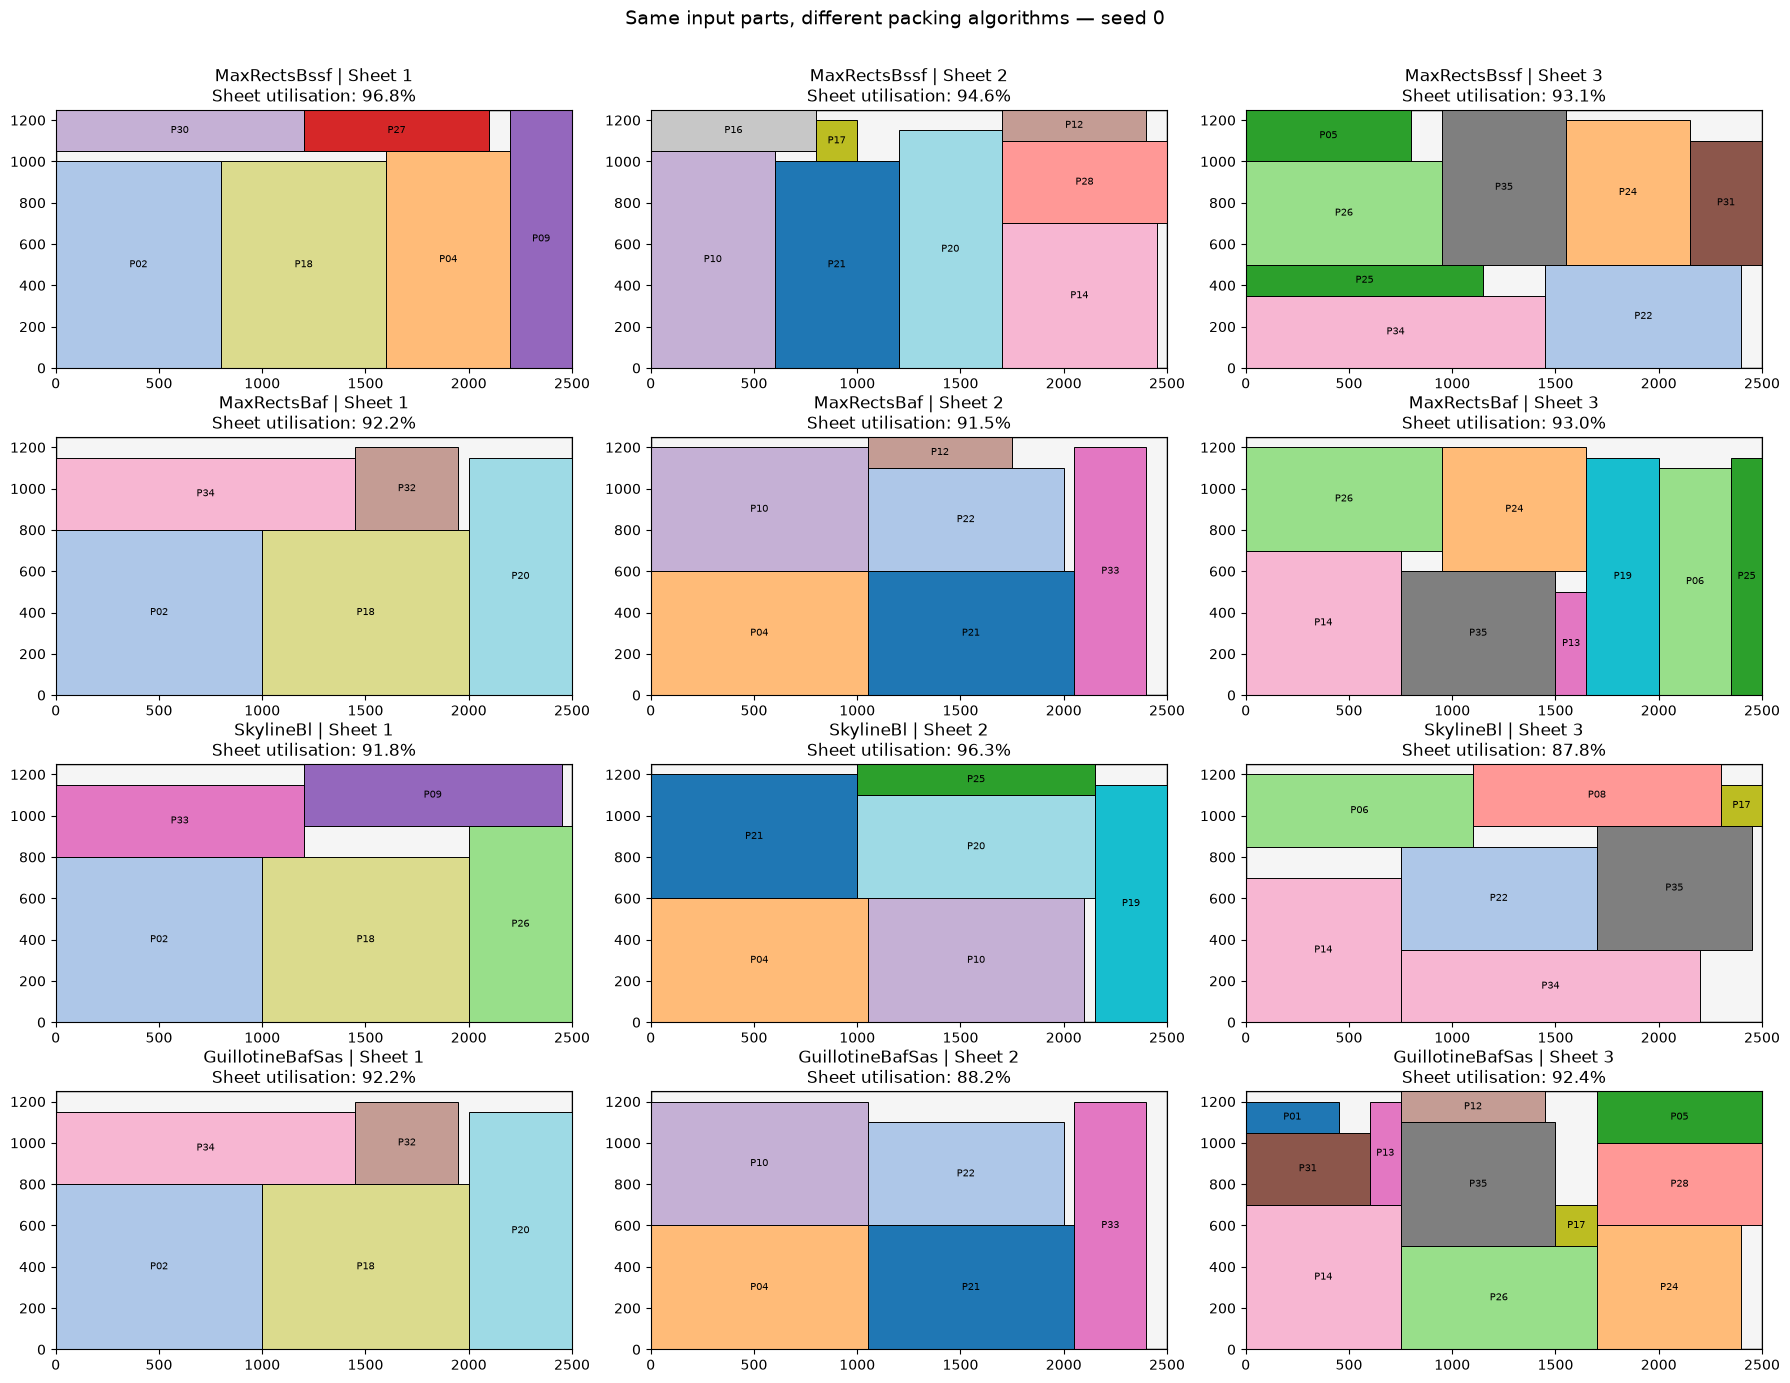

In [25]:
from matplotlib.patches import Rectangle


def plot_comparison(seed):
    case_parts = make_parts(seed)
    colours = plt.get_cmap("tab20")

    colour_by_id = {
        part_id: colours(i % 20)
        for i, (part_id, _, _) in enumerate(case_parts)
    }

    max_sheets = max(
        len(runs[(seed, algorithm.__name__)]["used_sheets"])
        for algorithm in algorithms
    )

    if max_sheets == 0:
        print("No parts packed.")
        return

    fig, axes = plt.subplots(
        len(algorithms),
        max_sheets,
        figsize=(6 * max_sheets, 3.5 * len(algorithms)),
        squeeze=False,
    )

    for row, algorithm in enumerate(algorithms):
        result = runs[(seed, algorithm.__name__)]

        for col in range(max_sheets):
            ax = axes[row, col]

            if col >= len(result["used_sheets"]):
                ax.axis("off")
                continue

            sheet_w, sheet_h = result["used_sheets"][col]
            sheet_part_area = 0

            ax.add_patch(
                Rectangle(
                    (0, 0), sheet_w, sheet_h,
                    facecolor="whitesmoke",
                    edgecolor="black",
                )
            )

            for b, x, y, w, h, part_id in result["placements"]:
                if b != col:
                    continue

                sheet_part_area += w * h

                ax.add_patch(
                    Rectangle(
                        (x, y), w, h,
                        facecolor=colour_by_id[part_id],
                        edgecolor="black",
                        linewidth=0.7,
                    )
                )

                ax.text(
                    x + w / 2,
                    y + h / 2,
                    part_id,
                    ha="center",
                    va="center",
                    fontsize=7,
                )

            sheet_utilisation = sheet_part_area / (sheet_w * sheet_h)

            ax.set(
                xlim=(0, sheet_w),
                ylim=(0, sheet_h),
                title=(
                    f"{algorithm.__name__} | Sheet {col + 1}\n"
                    f"Sheet utilisation: {sheet_utilisation:.1%}"
                ),
            )

            ax.set_aspect("equal")

    fig.suptitle(
        f"Same input parts, different packing algorithms — seed {seed}",
        fontsize=14,
    )

    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


plot_comparison(selected_seed)

### Summary statistics
How various algorithms compare on the generated datasets?

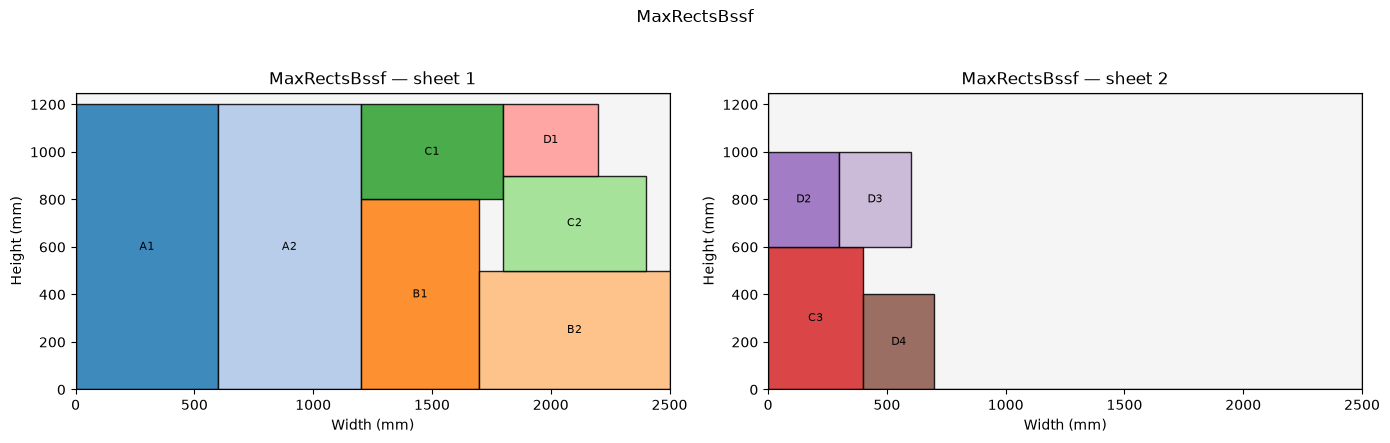

In [11]:
def plot_result(result, title=None):
    placements = result["placements"]
    used_sheets = result["used_sheets"]

    if not used_sheets:
        print("No parts were packed.")
        return

    fig, axes = plt.subplots(
        1, len(used_sheets),
        figsize=(7 * len(used_sheets), 4.5),
        squeeze=False,
    )

    colours = plt.get_cmap("tab20")
    part_colours = {
        part_id: colours(i % 20)
        for i, (part_id, _, _) in enumerate(parts)
    }

    for bin_index, (sheet_w, sheet_h) in enumerate(used_sheets):
        ax = axes[0, bin_index]

        ax.add_patch(Rectangle((0, 0), sheet_w, sheet_h,
                               facecolor="whitesmoke", edgecolor="black"))

        for b, x, y, w, h, part_id in placements:
            if b != bin_index:
                continue

            ax.add_patch(Rectangle((x, y), w, h,
                                   facecolor=part_colours[part_id],
                                   edgecolor="black", alpha=0.85))

            ax.text(x + w / 2, y + h / 2, part_id,
                    ha="center", va="center", fontsize=8)

        ax.set(xlim=(0, sheet_w), ylim=(0, sheet_h),
               xlabel="Width (mm)", ylabel="Height (mm)",
               title=f"{result['algorithm']} — sheet {bin_index + 1}")
        ax.set_aspect("equal")

    fig.suptitle(title or result["algorithm"])
    plt.tight_layout()
    plt.show()


plot_result(results[0])

Test rotation and sorting

In [12]:
variants = []

for algorithm in algorithms:
    for rotation in [True, False]:
        result = run_pack(algorithm, rotation=rotation)
        variants.append({
            "algorithm": algorithm.__name__,
            "rotation": rotation,
            "parts_packed": result["parts_packed"],
            "sheets_used": result["sheets_used"],
            "utilisation": result["utilisation"],
        })

pd.DataFrame(variants)

,algorithm,rotation,parts_packed,sheets_used,utilisation
0,MaxRectsBssf,True,11,2,0.5504
1,MaxRectsBssf,False,11,2,0.5504
2,MaxRectsBaf,True,11,2,0.5504
3,MaxRectsBaf,False,11,2,0.5504
4,SkylineBl,True,11,2,0.5504
5,SkylineBl,False,11,2,0.5504
6,GuillotineBafSas,True,11,2,0.5504
7,GuillotineBafSas,False,11,2,0.5504


In [15]:
# try sorting 
sort_variants = []

for sort_algo in [SORT_NONE, SORT_AREA, SORT_SSIDE]:
    result = run_pack(MaxRectsBssf, sort_algo=sort_algo)

    sort_variants.append({
        "sort": result["sort"],
        "parts_packed": result["parts_packed"],
        "sheets_used": result["sheets_used"],
        "utilisation": result["utilisation"],
    })

sort_summary = pd.DataFrame(sort_variants)
sort_summary

,sort,parts_packed,sheets_used,utilisation
0,Input order,11,2,0.5504
1,Area,11,2,0.5504
2,Shortest side,11,2,0.5504
